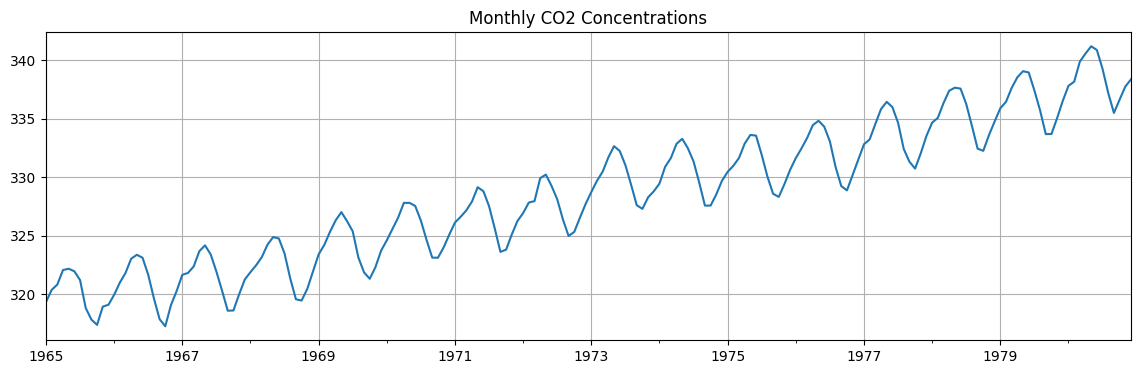

In [1]:
import sys
if 'google.colab' in sys.modules:
    !pip install -U -qq tsa-course pmdarima
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning, ValueWarning

warnings.filterwarnings("ignore")
warnings.simplefilter('ignore', ConvergenceWarning)
warnings.simplefilter('ignore', ValueWarning)
warnings.simplefilter('ignore', UserWarning)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import product
import time

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tools.eval_measures import mse
import pmdarima as pm

# Загрузка данных
co2 = pd.read_csv('https://zenodo.org/records/10951538/files/arima_co2.csv?download=1',
                  header=0,
                  names=['idx', 'co2'],
                  skipfooter=2)

co2['idx'] = pd.to_datetime(co2['idx'])
co2.set_index('idx', inplace=True)
co2.index.name = None

# Визуализация исходного ряда
co2['co2'].plot(grid=True, figsize=(14, 4), title="Monthly CO2 Concentrations")
plt.show()

In [2]:
# Разделение данных
co2_train = co2['co2'].iloc[:int(len(co2)*0.9)]
co2_test = co2['co2'].iloc[int(len(co2)*0.9):]

print(f"Train size: {len(co2_train)}, Test size: {len(co2_test)}")
print(f"Test period: {co2_test.index[0].date()} to {co2_test.index[-1].date()}")

# Тест ADF на исходных данных (для подтверждения нестационарности)
def adftest(series):
    out = adfuller(series, autolag='AIC')
    print(f'ADF Statistic: {out[0]:.2f}')
    print(f'p-value: {out[1]:.3f}')
    print("Вывод: Ряд нестационарен\n" if out[1] > 0.05 else "Вывод: Ряд стационарен\n")

adftest(co2_train)

Train size: 172, Test size: 20
Test period: 1979-05-01 to 1980-12-01
ADF Statistic: 0.50
p-value: 0.985
Вывод: Ряд нестационарен



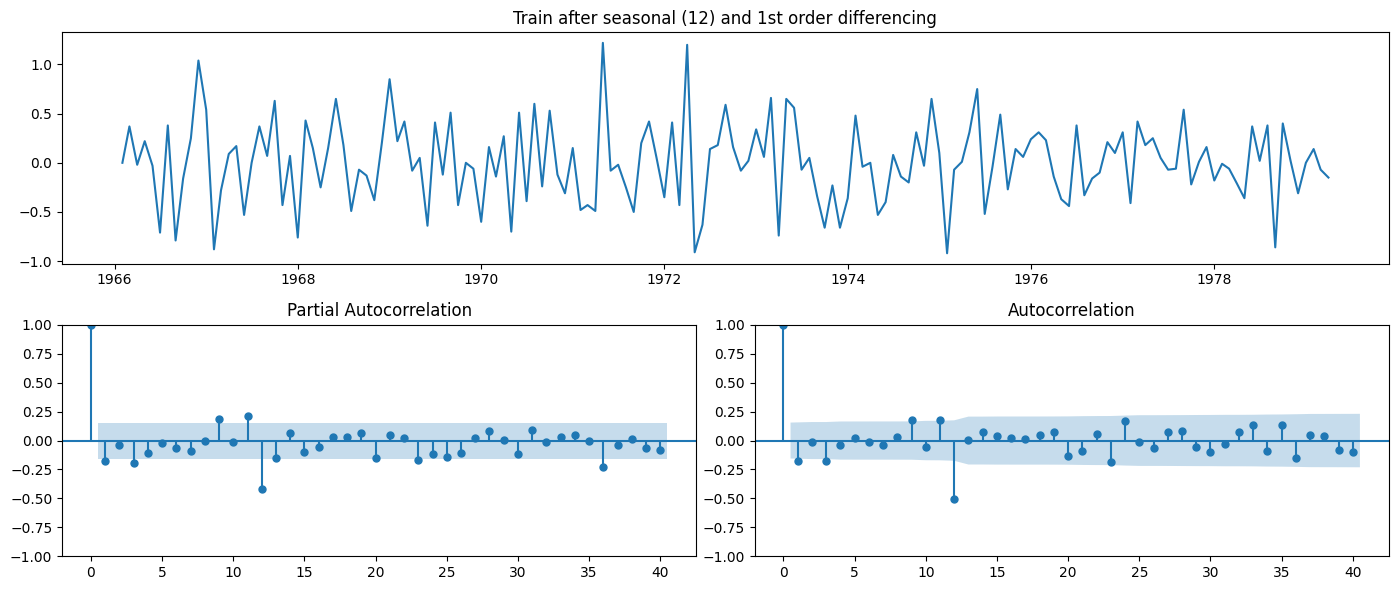

95% band: 0.155
significant ACF lags:  {1: -0.17, 3: -0.18, 9: 0.18, 11: 0.18, 12: -0.5, 23: -0.18, 24: 0.17}
significant PACF lags: {1: -0.18, 3: -0.2, 9: 0.19, 11: 0.23, 12: -0.46, 13: -0.17, 20: -0.19, 23: -0.22, 25: -0.18, 36: -0.34}


In [3]:
# Применяем сезонную (12) и обычную (1) разность
co2_train_diff = co2_train.diff(12).diff().dropna()

fig = plt.figure(figsize=(14, 6))
ax1 = plt.subplot2grid((2, 2), (0, 0), colspan=2)
ax1.plot(co2_train_diff)
ax1.set_title("Train after seasonal (12) and 1st order differencing")
ax2 = plt.subplot2grid((2, 2), (1, 0))
plot_pacf(co2_train_diff, lags=40, ax=ax2)
ax3 = plt.subplot2grid((2, 2), (1, 1))
plot_acf(co2_train_diff, lags=40, ax=ax3)
plt.tight_layout()
plt.show()

# Численное определение значимых лагов
band = 1.96 / np.sqrt(len(co2_train_diff))
co2_acf_vals = acf(co2_train_diff, nlags=40)[1:]
co2_pacf_vals = pacf(co2_train_diff, nlags=40)[1:]

print(f"95% band: {band:.3f}")
sig_acf = {int(k): round(float(co2_acf_vals[k - 1]), 2) for k in np.where(np.abs(co2_acf_vals) > band)[0] + 1}
sig_pacf = {int(k): round(float(co2_pacf_vals[k - 1]), 2) for k in np.where(np.abs(co2_pacf_vals) > band)[0] + 1}

print("significant ACF lags: ", sig_acf)
print("significant PACF lags:", sig_pacf)

In [4]:
# Определение сетки параметров
p_values = [0, 1, 2]
d_values = [1]
q_values = [0, 1, 2]
P_values = [0, 1]
D_values = [1]
Q_values = [0, 1]
s = 12

pdq = list(product(p_values, d_values, q_values))
PDQm = list(product(P_values, D_values, Q_values, [s]))

print(f"Number of total combinations: {len(pdq)*len(PDQm)}")

results = []
start = time.time()

for order in pdq:
    for seasonal_order in PDQm:
        try:
            model = SARIMAX(co2_train, order=order, seasonal_order=seasonal_order,
                            enforce_stationarity=False, enforce_invertibility=False)
            fit = model.fit(disp=False)

            pred = fit.get_prediction(co2_test.index[0], co2_test.index[-1]).summary_frame()
            test_mse = mse(co2_test, pred['mean'])
            test_mape = (abs(co2_test - pred['mean']) / co2_test).mean()

            results.append({
                'order': order,
                'seasonal_order': seasonal_order,
                'n_params': len(fit.params),
                'AIC': fit.aic,
                'BIC': fit.bic,
                'test MSE': test_mse,
                'test MAPE': test_mape
            })
        except:
            continue

print(f'Time required: {time.time() - start:.2f} sec')

co2_model_info = pd.DataFrame(results)
co2_model_info = co2_model_info.sort_values(by='AIC')

for metric in ["AIC", "BIC", "test MSE", "test MAPE"]:
    print(f"\n10 least {metric}")
    print(co2_model_info.nsmallest(10, metric)[['order', 'seasonal_order', metric]].to_string(index=False))

Number of total combinations: 36
Time required: 36.43 sec

10 least AIC
    order seasonal_order       AIC
(0, 1, 1)  (1, 1, 1, 12) 65.243322
(0, 1, 1)  (0, 1, 1, 12) 66.216929
(1, 1, 0)  (0, 1, 1, 12) 66.466380
(1, 1, 1)  (1, 1, 1, 12) 66.718505
(0, 1, 2)  (1, 1, 1, 12) 67.249668
(1, 1, 0)  (1, 1, 1, 12) 67.249925
(0, 1, 2)  (0, 1, 1, 12) 67.488057
(2, 1, 0)  (1, 1, 1, 12) 67.625810
(1, 1, 1)  (0, 1, 1, 12) 67.627570
(1, 1, 2)  (1, 1, 1, 12) 68.201320

10 least BIC
    order seasonal_order       BIC
(0, 1, 1)  (0, 1, 1, 12) 75.147130
(1, 1, 0)  (0, 1, 1, 12) 75.417200
(0, 1, 1)  (1, 1, 1, 12) 77.150256
(1, 1, 0)  (1, 1, 1, 12) 79.184352
(0, 1, 2)  (0, 1, 1, 12) 79.367310
(1, 1, 1)  (0, 1, 1, 12) 79.534505
(2, 1, 0)  (0, 1, 1, 12) 80.373442
(1, 1, 1)  (1, 1, 1, 12) 81.602174
(0, 1, 2)  (1, 1, 1, 12) 82.098734
(2, 1, 0)  (1, 1, 1, 12) 82.509478

10 least test MSE
    order seasonal_order  test MSE
(1, 1, 2)  (1, 1, 0, 12)  0.445151
(2, 1, 2)  (1, 1, 0, 12)  0.454929
(1, 1, 1)  (1, 1, 0,

In [5]:
print("Running auto_arima...")
co2_auto = pm.auto_arima(co2_train,
                         start_p=0, start_q=0,
                         test='adf',
                         max_p=3, max_q=3,
                         m=12,
                         start_P=0, start_Q=0,
                         max_P=2, max_Q=2,
                         seasonal=True,
                         d=None,
                         D=1,
                         trace=True,
                         error_action='ignore',
                         suppress_warnings=True,
                         stepwise=True)

print(f"\nAuto ARIMA Best Model: {co2_auto.order} x {co2_auto.seasonal_order}")
print(f"AIC: {co2_auto.aic():.2f}")

Running auto_arima...
Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=170.140, Time=0.04 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=116.893, Time=0.20 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=inf, Time=1.64 sec
 ARIMA(1,1,0)(0,1,0)[12]             : AIC=167.257, Time=0.07 sec
 ARIMA(1,1,0)(2,1,0)[12]             : AIC=112.261, Time=0.67 sec
 ARIMA(1,1,0)(2,1,1)[12]             : AIC=inf, Time=5.24 sec
 ARIMA(1,1,0)(1,1,1)[12]             : AIC=inf, Time=1.62 sec
 ARIMA(0,1,0)(2,1,0)[12]             : AIC=116.848, Time=0.39 sec
 ARIMA(2,1,0)(2,1,0)[12]             : AIC=114.093, Time=0.78 sec
 ARIMA(1,1,1)(2,1,0)[12]             : AIC=111.836, Time=0.96 sec
 ARIMA(1,1,1)(1,1,0)[12]             : AIC=116.214, Time=0.37 sec
 ARIMA(1,1,1)(2,1,1)[12]             : AIC=inf, Time=2.67 sec
 ARIMA(1,1,1)(1,1,1)[12]             : AIC=inf, Time=1.73 sec
 ARIMA(0,1,1)(2,1,0)[12]             : AIC=111.627, Time=0.51 sec
 ARIMA(0,1,1)(1,1,0)[12]       

In [6]:
top_models = co2_model_info.nsmallest(3, 'AIC')[['order', 'seasonal_order']].values.tolist()
candidates = {
    f"Grid_Top_{i+1}": (tuple(order), tuple(seasonal_order))
    for i, (order, seasonal_order) in enumerate(top_models)
}
candidates["Auto_ARIMA"] = (co2_auto.order, co2_auto.seasonal_order)

print("Candidates for final comparison:", candidates)

final_fits, final_preds, final_rows = {}, {}, []

for name, (order, seasonal_order) in candidates.items():
    fit = SARIMAX(endog=co2_train, order=order, seasonal_order=seasonal_order).fit(disp=False)
    pred = fit.get_prediction(co2_test.index[0], co2_test.index[-1]).summary_frame()
    final_fits[name], final_preds[name] = fit, pred

    _, jb_p, _, _ = fit.test_normality('jarquebera')[0]
    lb_p = fit.test_serial_correlation(method='ljungbox', lags=10)[0][1][-1]

    final_rows.append([
        name, order, seasonal_order, len(fit.params), fit.aic, fit.bic,
        mse(co2_test, pred['mean']), (abs(co2_test - pred['mean']) / co2_test).mean(),
        jb_p, lb_p
    ])

co2_compare = pd.DataFrame(final_rows, columns=[
    "model", "order", "seasonal_order", "n_params", "AIC", "BIC",
    "test MSE", "test MAPE", "Jarque-Bera p", "Ljung-Box p (lag 10)"
]).set_index("model")

print("\nFinal Comparison:")
print(co2_compare.to_string())

Candidates for final comparison: {'Grid_Top_1': ((0, 1, 1), (1, 1, 1, 12)), 'Grid_Top_2': ((0, 1, 1), (0, 1, 1, 12)), 'Grid_Top_3': ((1, 1, 0), (0, 1, 1, 12)), 'Auto_ARIMA': ((0, 1, 1), (2, 1, 0, 12))}

Final Comparison:
                order seasonal_order  n_params         AIC         BIC  test MSE  test MAPE  Jarque-Bera p  Ljung-Box p (lag 10)
model                                                                                                                           
Grid_Top_1  (0, 1, 1)  (1, 1, 1, 12)         4   92.321363  104.596980  0.668462   0.001884       0.579253              0.705232
Grid_Top_2  (0, 1, 1)  (0, 1, 1, 12)         3   90.470643   99.677356  0.668622   0.001883       0.608218              0.682944
Grid_Top_3  (1, 1, 0)  (0, 1, 1, 12)         3   91.389495  100.596207  0.661029   0.001874       0.658732              0.600336
Auto_ARIMA  (0, 1, 1)  (2, 1, 0, 12)         4  111.626929  123.902546  0.517895   0.001675       0.509654              0.699487


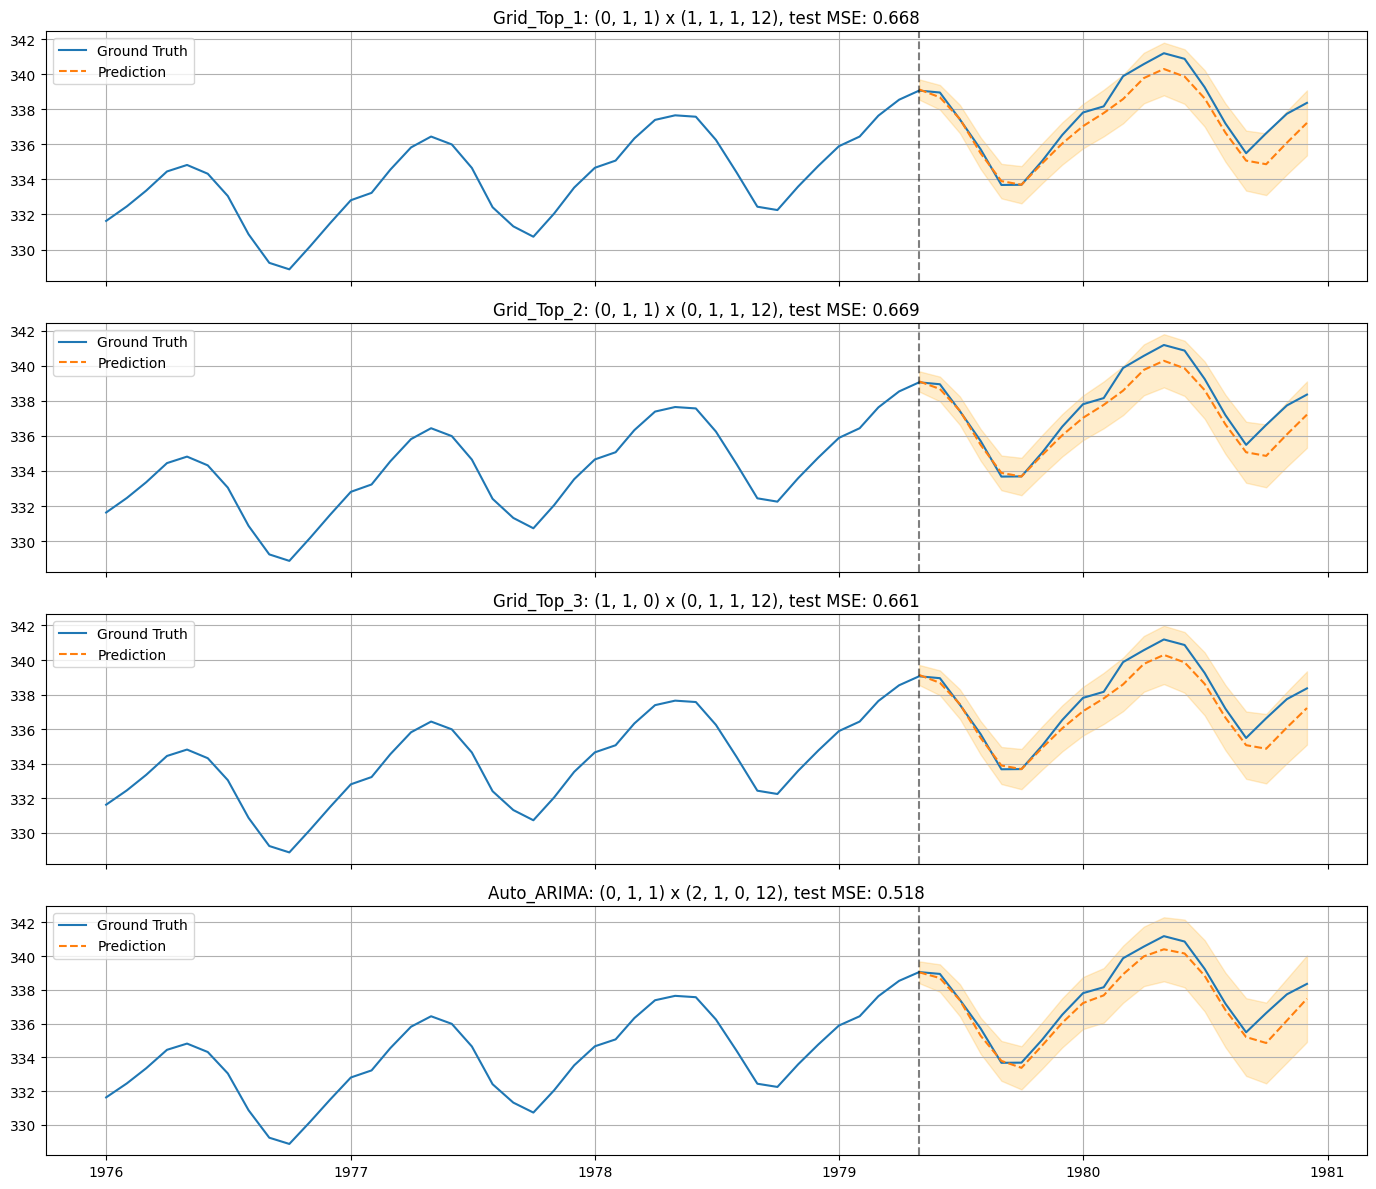

In [7]:
fig, axs = plt.subplots(len(candidates), 1, figsize=(14, 3 * len(candidates)), sharex=True)

for ax, (name, pred) in zip(axs, final_preds.items()):
    ax.plot(co2['co2'].iloc[-60:], label='Ground Truth')
    ax.plot(pred['mean'], label='Prediction', linestyle='--')
    ax.fill_between(co2_test.index, pred['mean_ci_lower'], pred['mean_ci_upper'],
                    color='orange', alpha=0.2)
    ax.axvline(co2_test.index[0], color='black', alpha=0.5, linestyle='--')

    order, seasonal_order = candidates[name]
    ax.set_title(f"{name}: {order} x {seasonal_order}, test MSE: {co2_compare.loc[name, 'test MSE']:.3f}")
    ax.grid()
    ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

Лучшая модель по AIC: Grid_Top_2
Параметры: ((0, 1, 1), (0, 1, 1, 12))


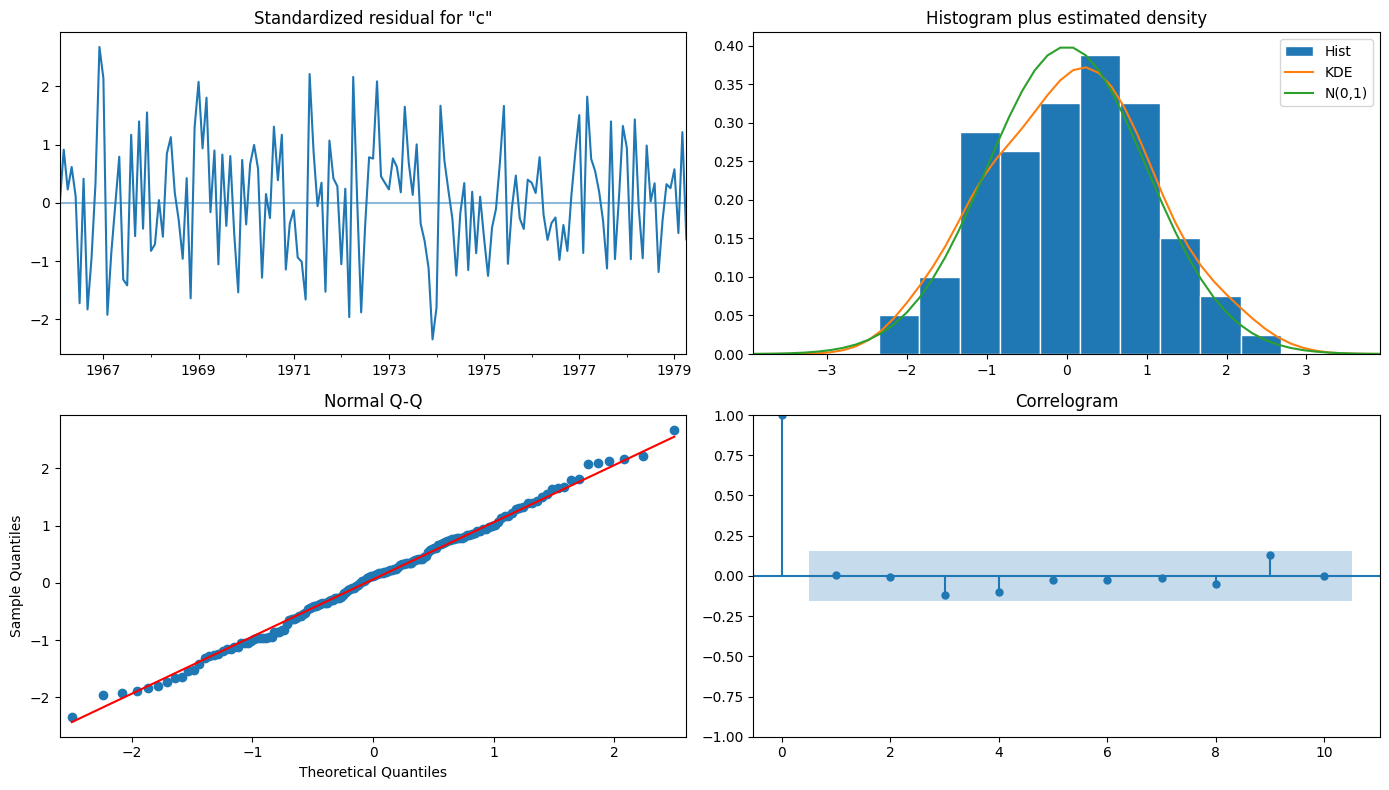


Коэффициенты лучшей модели:
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3058      0.065     -4.741      0.000      -0.432      -0.179
ma.S.L12      -0.9942      2.329     -0.427      0.670      -5.560       3.571
sigma2         0.0819      0.188      0.436      0.663      -0.286       0.450


In [8]:
# Находим имя лучшей модели по AIC
best_model_name = co2_compare['AIC'].idxmin()
print(f"Лучшая модель по AIC: {best_model_name}")
print(f"Параметры: {candidates[best_model_name]}")

# Получаем объект обученной модели
best_fit = final_fits[best_model_name]

# Диагностические графики остатков
best_fit.plot_diagnostics(figsize=(14, 8))
plt.tight_layout()
plt.show()

# Сводная таблица с коэффициентами модели
print("\nКоэффициенты лучшей модели:")
print(best_fit.summary().tables[1])

Проанализировали ряд концентрации CO₂. Визуальный анализ и декомпозиция выявили тренд и сезонность (период 12). Тест ADF подтвердил нестационарность (p > 0.05), поэтому применили сезонное и обычное дифференцирование (d=1, D=1). По ACF/PACF определили порядки (0,1,1) для несезонной части и сезонные компоненты.

Сравнили 4 финальные модели: 3 лучшие из Grid Search (36 комбинаций) и 1 от auto_arima. По AIC/BIC лучшая — SARIMA(0,1,1)(0,1,1,12) (AIC ≈ 90.5). По ошибке на тесте лучшая — SARIMA(0,1,1)(2,1,0,12) от auto_arima (MSE ≈ 0.518, MAPE ≈ 0.17%). Все модели прошли диагностику остатков — остатки нормальны, автокорреляции нет.

Обе стратегии поиска сошлись на структуре (0,1,1), что подтверждает корректность ручного анализа. Для прогноза рекомендуем SARIMA(0,1,1)(2,1,0,12) — минимальная ошибка. Для простоты — SARIMA(0,1,1)(0,1,1,12) с лучшим AIC.